In [1]:
import yfinance as yf
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import numpy as np

In [4]:
end = dt.date(2024,12,1)
start = dt.date(2022,1,1)
btc = pd.DataFrame(yf.download('BTC-USD',start,end,interval = '1mo')['Close'].pct_change())
gold = pd.DataFrame(yf.download('GC=F',start,end,interval = '1mo')['Close'].pct_change())

print(gold.head())
print(btc.head())

/tmp/ipython-input-4-2690445435.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  btc = pd.DataFrame(yf.download('BTC-USD',start,end,interval = '1mo')['Close'].pct_change())
[*********************100%***********************]  1 of 1 completed
/tmp/ipython-input-4-2690445435.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  gold = pd.DataFrame(yf.download('GC=F',start,end,interval = '1mo')['Close'].pct_change())
[*********************100%***********************]  1 of 1 completed

Ticker          GC=F
Date                
2022-01-01       NaN
2022-02-01  0.058162
2022-03-01  0.026219
2022-04-01 -0.020470
2022-06-01 -0.055099
Ticker       BTC-USD
Date                
2022-01-01       NaN
2022-02-01  0.122394
2022-03-01  0.054301
2022-04-01 -0.171806
2022-05-01 -0.157035


In [5]:
# end = dt.date(2024,12,1)
# start = dt.date(2010,1,1)
# btc = np.log10(yf.download('BTC-USD',start,end)['Adj Close'])
# gold =np.log10(yf.download('GC=F',start,end)['Adj Close'])



In [6]:
df = pd.concat([btc,gold],axis=1)
df.columns = ['BTC','GOLD']
df.dropna(inplace=True)
print(df.head())

                 BTC      GOLD
Date                          
2022-02-01  0.122394  0.058162
2022-03-01  0.054301  0.026219
2022-04-01 -0.171806 -0.020470
2022-06-01 -0.377688 -0.055099
2022-07-01  0.179541 -0.022837


In [7]:

df['equal'] = df['BTC']+df['GOLD']
df['btc_ratio'] = (df['BTC'].shift(1)/df['equal'].shift(1))
df['btc_ratio_hold'] = np.where(df['btc_ratio'] < 0, 0, np.where(df['btc_ratio'] > 1, 1, df['btc_ratio']))
df['gold_ratio'] = (df['GOLD'].shift(1)/df['equal'].shift(1))
df['gold_ratio_hold'] = np.where(df['gold_ratio'] <0,0,np.where(df['gold_ratio']>1,1,df['gold_ratio']))

df['port_rets'] = df['btc_ratio']*df['BTC'] + df['gold_ratio']*df['GOLD']
df['port_rets_hold'] = df['btc_ratio_hold']*df['BTC'] + df['gold_ratio_hold']*df['GOLD']

df['BTC_cum_rets'] = (1+df['BTC']).cumprod()
df['GOLD_cum_rets'] = (1+df['GOLD']).cumprod()
df['port_cum_rets'] = (1+df['port_rets']).cumprod()

df.dropna(inplace=True)




df

,BTC,GOLD,equal,btc_ratio,btc_ratio_hold,gold_ratio,gold_ratio_hold,port_rets,port_rets_hold,BTC_cum_rets,GOLD_cum_rets,port_cum_rets
Date,,,,,,,,,,,,
2022-03-01,0.054301,0.026219,0.080520,0.677875,0.677875,0.322125,0.322125,0.045255,0.045255,1.183341,1.085905,1.045255
2022-04-01,-0.171806,-0.020470,-0.192276,0.674382,0.674382,0.325618,0.325618,-0.122528,-0.122528,0.980037,1.063677,0.917182
2022-06-01,-0.377688,-0.055099,-0.432787,0.893539,0.893539,0.106461,0.106461,-0.343345,-0.343345,0.609888,1.005070,0.602272
2022-07-01,0.179541,-0.022837,0.156704,0.872689,0.872689,0.127311,0.127311,0.153776,0.153776,0.719388,0.982117,0.694887
2022-08-01,-0.140856,-0.028419,-0.169275,1.145732,1.000000,-0.145732,0.000000,-0.157241,-0.140856,0.618058,0.954206,0.585622
2022-09-01,-0.030822,-0.029426,-0.060248,0.832113,0.832113,0.167887,0.167887,-0.030588,-0.030588,0.599009,0.926128,0.567710
2022-10-01,0.054755,-0.015941,0.038814,0.511590,0.511590,0.488410,0.488410,0.020226,0.020226,0.631807,0.911365,0.579192
2022-11-01,-0.162336,0.067302,-0.095034,1.410697,1.000000,-0.410697,0.000000,-0.256648,-0.162336,0.529242,0.972702,0.430544
2022-12-01,-0.036175,0.042211,0.006036,1.708194,1.000000,-0.708194,0.000000,-0.091687,-0.036175,0.510097,1.013760,0.391068


In [8]:
sharpe = df['port_cum_rets'].mean()/df['port_cum_rets'].std()
print(sharpe)

1.1183417932466784


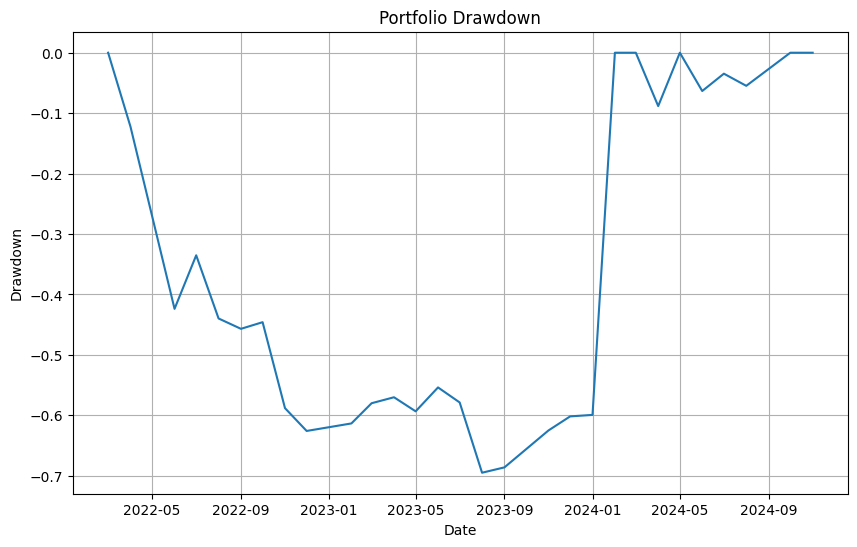

In [9]:

# Calculate drawdown hold
df['peak'] = df['port_cum_rets'].cummax()
df['drawdown'] = (df['port_cum_rets'] - df['peak']) / df['peak']


# Plot drawdown
plt.figure(figsize=(10, 6))
plt.plot(df['drawdown'])
plt.title('Portfolio Drawdown')
plt.xlabel('Date')
plt.ylabel('Drawdown')
plt.grid(True)
plt.show()

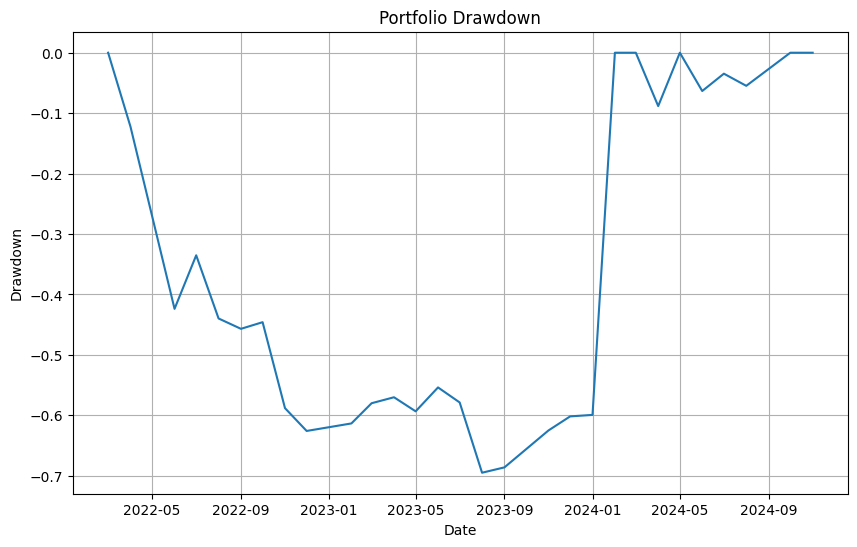

In [10]:
df['peak'] = df['port_cum_rets'].cummax()
df['drawdown'] = (df['port_cum_rets'] - df['peak']) / df['peak']


# Plot drawdown
plt.figure(figsize=(10, 6))
plt.plot(df['drawdown'])
plt.title('Portfolio Drawdown')
plt.xlabel('Date')
plt.ylabel('Drawdown')
plt.grid(True)
plt.show()

/tmp/ipython-input-12-1286344328.py:4: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "b-" (-> color='b'). The keyword argument will take precedence.
  ax1.plot(df.index, df['GOLD_cum_rets'], 'b-', label='GOLD',color ='yellow')
/tmp/ipython-input-12-1286344328.py:6: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax1.plot(df.index, df['BTC_cum_rets'], 'r-', label='BTC',color ='red')
/tmp/ipython-input-12-1286344328.py:8: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "g-" (-> color='g'). The keyword argument will take precedence.
  ax1.plot(df.index, df['port_cum_rets'], 'g-', label='Portfolio',color ='green')


KeyError: 'port_cum_rets_hold'

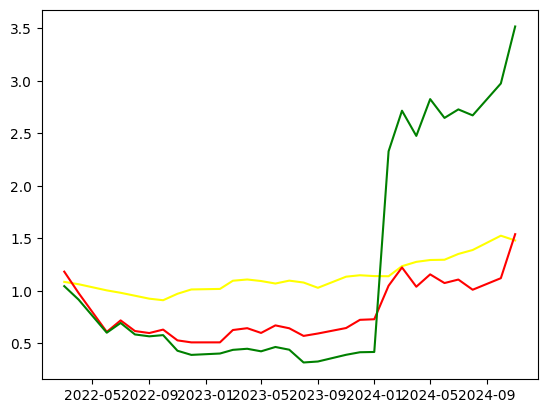

In [12]:
fig, ax1 = plt.subplots()

# Plot the first dataset
ax1.plot(df.index, df['GOLD_cum_rets'], 'b-', label='GOLD',color ='yellow')

ax1.plot(df.index, df['BTC_cum_rets'], 'r-', label='BTC',color ='red')

ax1.plot(df.index, df['port_cum_rets'], 'g-', label='Portfolio',color ='green')
ax1.plot(df.index, df['port_cum_rets_hold'], color = 'blue')


# Add a title
plt.title('GOLD VS BTC')

# Show the plot
plt.show()